# Del cajero a la billetera: cómo cambió la forma de pagar en Argentina

**Pregunta:** ¿cuánto creció el uso de pagos digitales (transferencias, billeteras, QR) frente al efectivo, y qué esperar para los próximos 12 meses?

**Fuentes oficiales:**
- BCRA, *Informe Mensual de Pagos Minoristas*, series en Excel (enero 2017 – septiembre 2026).
- INDEC, IPC nivel general nacional (para pasar montos a pesos constantes).

**Herramientas:** Python (pandas, statsmodels, matplotlib), con Claude Code como copiloto.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.ticker as mt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings; warnings.filterwarnings('ignore')

VIOL, LILA, TINTA, GRIS, SUAVE = '#6b63d0', '#a29bf2', '#1c1c27', '#8a88a6', '#d9d5f2'
plt.rcParams.update({'figure.figsize': (10, 4.6), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': GRIS, 'axes.labelcolor': TINTA, 'xtick.color': GRIS, 'ytick.color': GRIS,
                     'axes.titleweight': 'bold', 'axes.titlesize': 14, 'axes.titlelocation': 'left',
                     'font.size': 11, 'axes.grid': True, 'grid.color': '#eeeef3', 'grid.linewidth': .8})
FIG = '../figuras/'
miles = mt.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.'))

## 1. Carga y control de calidad

In [2]:
df = pd.read_csv('../data/pagos_largo.csv', parse_dates=['fecha'])
ipc = pd.read_csv('../data/raw/ipc_nacional.csv', parse_dates=['indice_tiempo']).rename(columns={'indice_tiempo': 'fecha'})
ipc = ipc.set_index('fecha').iloc[:, 0]
print(f'{len(df):,} filas | {df[["hoja","serie","medida"]].drop_duplicates().shape[0]} series | {df.fecha.min():%m/%Y} a {df.fecha.max():%m/%Y}'.replace(',', '.'))

def serie(hoja, contiene, medida='Cantidad'):
    m = (df.hoja == hoja) & df.serie.str.contains(contiene, regex=False) & df.medida.str.startswith(medida)
    s = df[m].groupby('fecha').valor.sum()
    return s.asfreq('MS')

push_total = df[(df.hoja=='Transferencias de fondos') & (df.serie=='Transferencias inmediatas | Transferencias inmediatas "push"') & (df.medida=='Cantidad')].set_index('fecha').valor.asfreq('MS')
canales = {c: serie('Series push apertura', f'fondos (pesos) | {c}') for c in ['ATM', 'BEE', 'HB', 'MB']}
camara = serie('Series push apertura', 'cámara electrónica de compensación (pesos)')
suma = sum(canales.values()) + camara
dif = (suma / push_total - 1).dropna().abs().max()
print(f'Control: la suma de canales + cámara coincide con el total de transferencias push (diferencia máxima {dif:.4%})')

10.558 filas | 124 series | 01/2017 a 09/2026
Control: la suma de canales + cámara coincide con el total de transferencias push (diferencia máxima 0.0000%)


## 2. Del efectivo a la transferencia
Cantidad de operaciones por mes: extracciones en cajeros automáticos contra transferencias inmediatas.

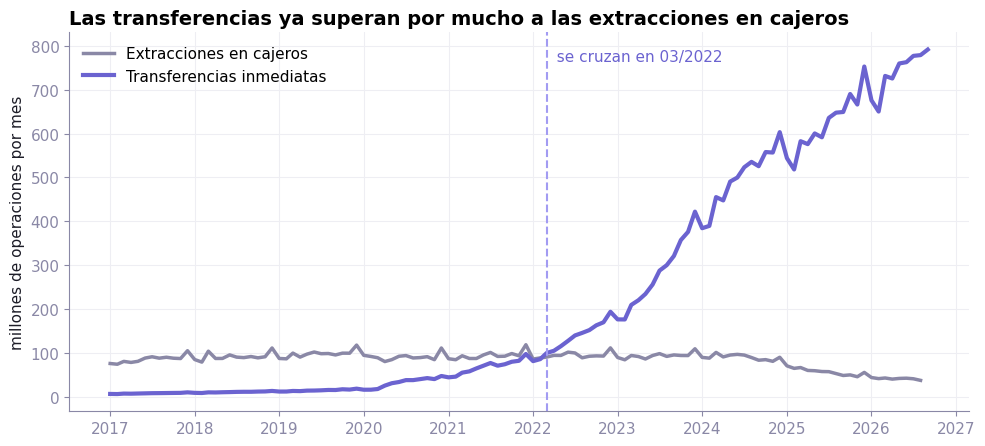

09/2026: 792 M transferencias vs 37 M extracciones (21.2 veces). En 01/2017 la relación era 0.08.


In [3]:
extr = serie('Resto', 'Extracciones en cajeros automáticos')
fig, ax = plt.subplots()
ax.plot(extr.index, extr / 1e6, color=GRIS, lw=2.5, label='Extracciones en cajeros')
ax.plot(push_total.index, push_total / 1e6, color=VIOL, lw=3, label='Transferencias inmediatas')
ambos = pd.concat([push_total, extr], axis=1, keys=['tr', 'ex']).dropna()
cruce = ambos[ambos.tr > ambos.ex].index.min()
ax.axvline(cruce, color=LILA, ls='--', lw=1.5); ax.text(cruce, ax.get_ylim()[1]*.92, f'  se cruzan en {cruce:%m/%Y}', color=VIOL)
ax.set_title('Las transferencias ya superan por mucho a las extracciones en cajeros'); ax.set_ylabel('millones de operaciones por mes')
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(FIG + '1_efectivo_vs_transferencias.png', dpi=160); plt.show()
u = push_total.last_valid_index()
print(f'{u:%m/%Y}: {push_total[u]/1e6:,.0f} M transferencias vs {extr.dropna().iloc[-1]/1e6:,.0f} M extracciones '
      f'({push_total[u]/extr.dropna().iloc[-1]:.1f} veces). En 01/2017 la relación era {push_total.iloc[0]/extr.iloc[0]:.2f}.')

## 3. ¿Por dónde se transfiere?
Las transferencias "push" en pesos se reparten entre las redes bancarias (cajero, banca empresa, home banking, app del banco) y la cámara electrónica de compensación, por donde pasan buena parte de las transferencias que involucran billeteras con CVU.

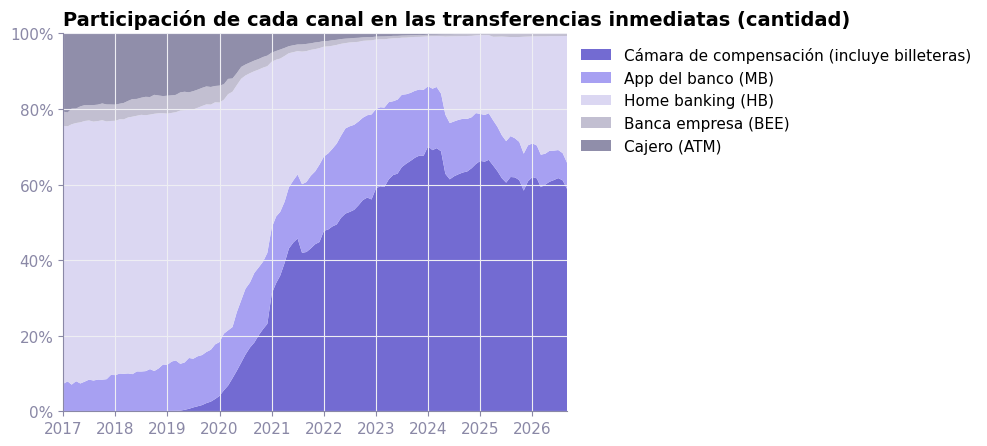

fecha                                        01/2017  09/2026
Cámara de compensación (incluye billeteras)    0.000    0.588
App del banco (MB)                             0.073    0.069
Home banking (HB)                              0.682    0.336
Banca empresa (BEE)                            0.038    0.006
Cajero (ATM)                                   0.207    0.001


In [4]:
part = pd.DataFrame({'Cámara de compensación (incluye billeteras)': camara, 'App del banco (MB)': canales['MB'],
                     'Home banking (HB)': canales['HB'], 'Banca empresa (BEE)': canales['BEE'], 'Cajero (ATM)': canales['ATM']})
part = part.div(part.sum(axis=1), axis=0).dropna()
fig, ax = plt.subplots()
ax.stackplot(part.index, part.T.values, labels=part.columns, colors=[VIOL, LILA, SUAVE, '#bfbccf', GRIS], alpha=.95)
ax.yaxis.set_major_formatter(mt.PercentFormatter(1)); ax.set_ylim(0, 1); ax.margins(x=0)
ax.set_title('Participación de cada canal en las transferencias inmediatas (cantidad)')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False); plt.tight_layout()
plt.savefig(FIG + '2_canales.png', dpi=160); plt.show()
print(part.iloc[[0, -1]].round(3).T.rename(columns=lambda d: f'{d:%m/%Y}'))

## 4. Pagos con QR y billeteras
Pagos con transferencia interoperables (QR) y cuentas de pago de las billeteras (cantidad con saldo y saldo en pesos constantes).

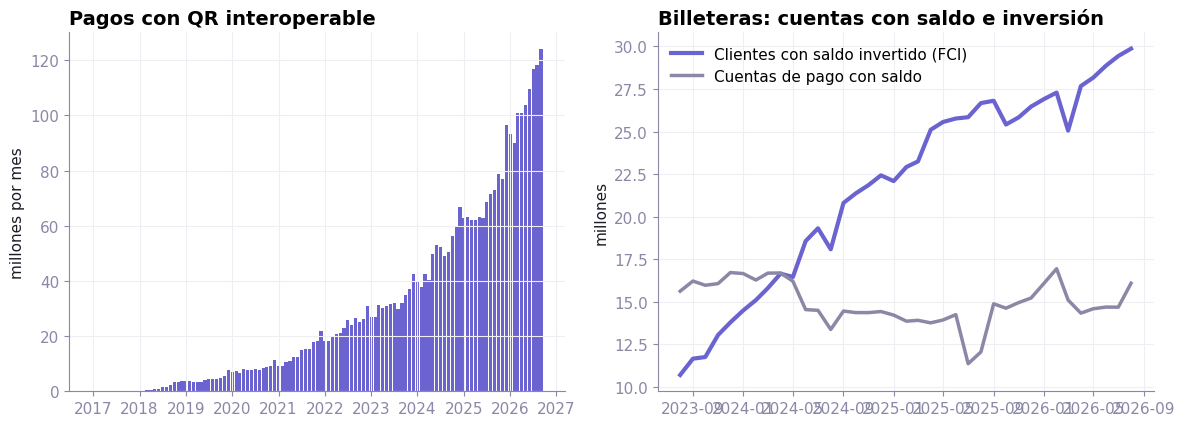

QR: 123.9 M pagos en 09/2026; últimos 12 meses vs. 12 anteriores: +57%
Clientes con FCI en billeteras: 10.7 M (08/2023) → 29.9 M (08/2026)
Saldo real en cuentas de pago: -1% desde 08/2023 (pesos de 08/2026)


In [5]:
qr = serie('Transferencias de fondos', 'Pagos con transferencia interoperables')
cta = serie('Cuentas de pago y fondos invert', 'Cuentas de pago', 'Cantidad')
saldo = serie('Cuentas de pago y fondos invert', 'Cuentas de pago', 'Saldo')
fci = serie('Cuentas de pago y fondos invert', 'Saldos en fondos comunes', 'Cantidad')
base = ipc[saldo.dropna().index.max()]
saldo_real = (saldo / ipc.reindex(saldo.index) * base).dropna()

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
q = qr[qr > 0].dropna()
axs[0].bar(q.index, q / 1e6, width=25, color=VIOL); axs[0].set_title('Pagos con QR interoperable'); axs[0].set_ylabel('millones por mes')
axs[1].plot(fci.index, fci / 1e6, color=VIOL, lw=3, label='Clientes con saldo invertido (FCI)')
axs[1].plot(cta.index, cta / 1e6, color=GRIS, lw=2.5, label='Cuentas de pago con saldo')
axs[1].set_title('Billeteras: cuentas con saldo e inversión'); axs[1].set_ylabel('millones'); axs[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG + '3_qr_billeteras.png', dpi=160); plt.show()
a, b = q.index[q.index.year == q.index.max().year - 1], q.index[-12:]
print(f'QR: {q.iloc[-1]/1e6:,.1f} M pagos en {q.index[-1]:%m/%Y}; últimos 12 meses vs. 12 anteriores: {q[-12:].sum()/q[-24:-12].sum()-1:+.0%}')
print(f'Clientes con FCI en billeteras: {fci.dropna().iloc[0]/1e6:.1f} M ({fci.dropna().index[0]:%m/%Y}) → {fci.dropna().iloc[-1]/1e6:.1f} M ({fci.dropna().index[-1]:%m/%Y})')
print(f'Saldo real en cuentas de pago: {saldo_real.iloc[-1]/saldo_real.iloc[0]-1:+.0%} desde {saldo_real.index[0]:%m/%Y} (pesos de {saldo.dropna().index.max():%m/%Y})')

## 5. Ticket promedio real de una transferencia
Monto por operación en pesos constantes (de septiembre 2026), usando el IPC.

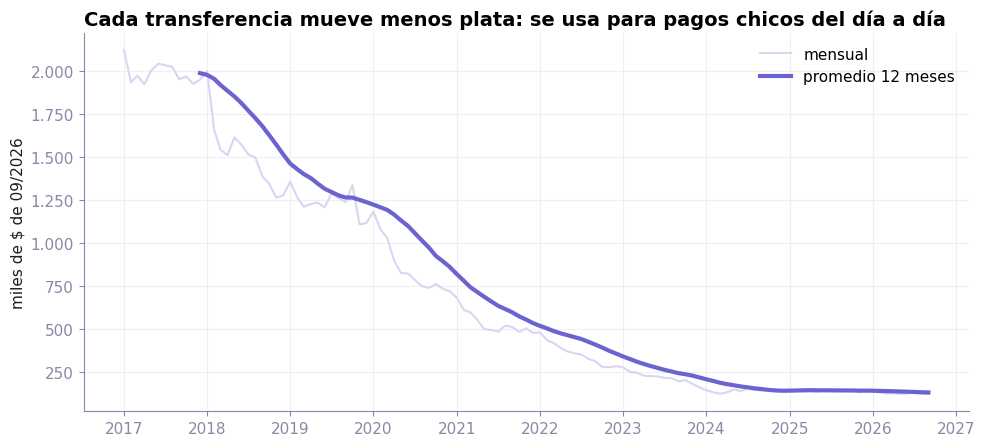

Ticket real promedio: 1.984.790 (12 meses a 12/2017) → 133.356 (12 meses a 09/2026). -93%


In [6]:
monto = df[(df.hoja=='Transferencias de fondos') & (df.serie=='Transferencias inmediatas | Transferencias inmediatas "push"') & (df.medida=='Monto nominal')].set_index('fecha').valor.asfreq('MS')
ult = monto.last_valid_index()
ticket = (monto / push_total / ipc.reindex(monto.index) * ipc[ult]).dropna()
t12 = ticket.rolling(12).mean()
fig, ax = plt.subplots()
ax.plot(ticket.index, ticket / 1e3, color=SUAVE, lw=1.5, label='mensual')
ax.plot(t12.index, t12 / 1e3, color=VIOL, lw=3, label='promedio 12 meses')
ax.yaxis.set_major_formatter(miles); ax.set_ylabel(f'miles de $ de {ult:%m/%Y}')
ax.set_title('Cada transferencia mueve menos plata: se usa para pagos chicos del día a día'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG + '4_ticket_real.png', dpi=160); plt.show()
print(f'Ticket real promedio: {t12.dropna().iloc[0]:,.0f} (12 meses a {t12.dropna().index[0]:%m/%Y}) → {t12.iloc[-1]:,.0f} (12 meses a {ult:%m/%Y}), {t12.iloc[-1]/t12.dropna().iloc[0]-1:+.0%}'.replace(',', '.'))

## 6. Forecast de transferencias inmediatas (12 meses)
Se comparan tres modelos con un backtest: se entrenan hasta septiembre 2025 y se mide el error contra los 12 meses reales siguientes.
- **Naive estacional:** el mismo mes del año anterior.
- **Holt-Winters:** tendencia amortiguada y estacionalidad multiplicativa.
- **SARIMA (1,1,1)(0,1,1,12)** sobre el logaritmo de la serie.

In [7]:
y = push_total.dropna()
corte = y.index[-13]
train, test = y[:corte], y[corte:][1:]
h = len(test)
mape = lambda p: float(np.mean(np.abs(test.values - np.asarray(p)) / test.values))

p_naive = y.shift(12)[test.index]
hw = ExponentialSmoothing(train, trend='add', damped_trend=True, seasonal='mul', seasonal_periods=12).fit()
p_hw = hw.forecast(h)
sar = SARIMAX(np.log(train), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
p_sar = np.exp(sar.forecast(h))
res = pd.Series({'Naive estacional': mape(p_naive), 'Holt-Winters': mape(p_hw), 'SARIMA': mape(p_sar)}).sort_values()
print('Error medio absoluto % (MAPE) en el backtest:'); print((res * 100).round(2).astype(str) + ' %')
mejor = res.index[0]

Error medio absoluto % (MAPE) en el backtest:
Holt-Winters         3.47 %
SARIMA               9.24 %
Naive estacional    19.39 %
dtype: object


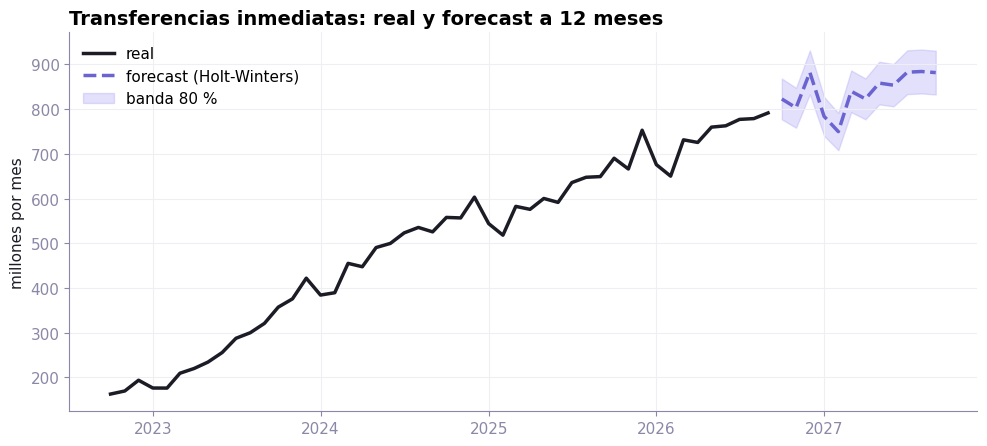

Próximos 12 meses: 10.07 mil millones de transferencias, +15% contra los últimos 12 meses.


In [8]:
# modelo final: el mejor del backtest, reentrenado con toda la serie
if mejor == 'SARIMA':
    m = SARIMAX(np.log(y), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    f = m.get_forecast(12); pred = np.exp(f.predicted_mean); ci = np.exp(f.conf_int(alpha=.2))
else:
    m = ExponentialSmoothing(y, trend='add', damped_trend=True, seasonal='mul', seasonal_periods=12).fit()
    pred = m.forecast(12); e = res[mejor] * 1.25   # MAPE ≈ 0,8 σ → banda ~80 % a partir del error real del backtest
    ci = pd.DataFrame({'lo': pred * (1 - 1.28 * e), 'hi': pred * (1 + 1.28 * e)})
fig, ax = plt.subplots()
desde = y.index[-48]
ax.plot(y[desde:].index, y[desde:] / 1e6, color=TINTA, lw=2.5, label='real')
ax.plot(pred.index, pred / 1e6, color=VIOL, lw=2.5, ls='--', label=f'forecast ({mejor})')
ax.fill_between(pred.index, ci.iloc[:, 0] / 1e6, ci.iloc[:, 1] / 1e6, color=LILA, alpha=.3, label='banda 80 %')
ax.set_title('Transferencias inmediatas: real y forecast a 12 meses'); ax.set_ylabel('millones por mes'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG + '5_forecast.png', dpi=160); plt.show()
crec = pred.sum() / y[-12:].sum() - 1
print(f'Próximos 12 meses: {pred.sum()/1e9:,.2f} mil millones de transferencias, {crec:+.0%} contra los últimos 12 meses.')
pd.DataFrame({'forecast': pred.round(0), 'banda_baja': ci.iloc[:, 0].round(0), 'banda_alta': ci.iloc[:, 1].round(0)}).to_csv('../data/forecast_transferencias.csv')

## 7. Conclusiones
- **El efectivo perdió terreno.** En enero 2017 había 12 extracciones en cajeros por cada transferencia. En marzo 2022 se cruzaron, y en 2026 ya hay unas 21 transferencias por cada extracción.
- **Las billeteras cambiaron el canal.** La cámara de compensación, donde operan las billeteras con CVU, pasó de 0 % a cerca del 59 % de las transferencias. El cajero como canal para transferir prácticamente desapareció.
- **Las billeteras también se usan para invertir.** Los clientes con saldo en fondos comunes dentro de billeteras se triplicaron en tres años, mientras el saldo real en las cuentas de pago se mantuvo estable.
- **La transferencia reemplazó al efectivo en pagos chicos.** El ticket real promedio cayó más de 90 % desde 2017, y los pagos con QR crecieron 57 % en el último año.
- **El crecimiento sigue, pero más lento.** Holt-Winters fue el mejor modelo en el backtest, con 3,5 % de error contra 19 % del naive estacional. Proyecta +15 % para los próximos 12 meses, lejos de los años de adopción masiva (+100 % anual entre 2020 y 2023).